# M03-5 | 不靠校準的 qparams：Derived 與 FixedQParams

到目前為止，每個位置的 scale 與 zero point 都由 observer 看資料算出來。但有些 tensor 的 qparams 不該靠校準決定：

| spec | qparams 從哪來 | 例子 |
|---|---|---|
| `DerivedQuantizationSpec` | 由其他位置的 observer 算出來 | conv 的 bias：scale = activation scale × weight scale |
| `FixedQParamsQuantizationSpec` | 寫死在 spec 裡，與資料無關 | sigmoid 的輸出：值域固定在 (0, 1)；模型輸出要符合下游的定點格式（例如 Q3.12） |

- **A.** Derived：bias 量化成 int32，scale 由 activation 與 weight 推導。
- **B.** FixedQParams：sigmoid 的輸出用固定的 scale，不受校準資料影響；以及模型輸出直接交給整數運算的 DSP 時，怎麼用它對齊格式。

In [1]:
import copy
from typing import Any, cast

import torch

from common.graph_utils import observer_nodes
from common.models import example_inputs, get_model
from common.pt2e import (
    DerivedQuantizationSpec,
    FixedQParamsQuantizationSpec,
    Quantizer,
    annotate_input_qspec_map,
    annotate_output_qspec,
    convert_pt2e,
    export_module,
    prepare_pt2e,
    quiet,
)
from common.qspecs import act_spec, weight_spec
from common.viz import draw_stages, table

quiet()
_ = torch.manual_seed(0)
CONV2D = torch.ops.aten.conv2d.default
SIGMOID = torch.ops.aten.sigmoid.default

## A. Derived：bias 的 scale 由 activation 與 weight 推導

整數 conv 代入 $x = s_x(q_x - z_x)$、$w = s_w(q_w - z_w)$，$z_x$、$z_w$ 是各自的 zero point。
一個 output channel 的乘加展開後，公因子是 $s_x s_w$（per-channel weight 時，每個 output channel 一個 $s_w$）：

$$
\sum x w = s_x s_w \Big( \sum q_x q_w - z_w \sum q_x - z_x \sum q_w + N z_x z_w \Big)
$$

$N$ 是這個 channel 加總的項數。bias 用同一個 scale 量化成 int32，zero point 取 0，才能把 $q_b$ 直接加進括號：

$$
y \approx s_x s_w \Big( \sum q_x q_w - z_w \sum q_x - z_x \sum q_w + N z_x z_w + q_b \Big),
\qquad q_b = \operatorname{round}\!\Big(\frac{b}{s_x s_w}\Big) \tag{1}
$$

$z_x$、$z_w$ 只在括號的整數項裡，不會算出一個 bias zero point。
常數項 $N z_x z_w$、$z_x \sum q_w$ 可以另折進 $q_b$；$z_w \sum q_x$ 依賴當下的輸入，所以 weight 通常取 symmetric（$z_w = 0$）。
下面的 `weight_spec()` 就是這個設定。式 (1) 的 $q_b$ 只量化 bias 本身，還沒有折進那些常數項。

這是整數推論常見的做法，實際要求依後端而定（M10 的 VPU 範例就要求 int32 bias）。
既然 bias 的 scale 由別人決定，它就不能自己校準，只能推導：`DerivedQuantizationSpec` 的 `derived_from` 列出依賴的位置，
`derive_qparams_fn` 收到那些位置的 observer（順序與 `derived_from` 相同），回傳 (scale, zero point)。

In [2]:
def derive_bias_qparams(obs_or_fqs):
    act_scale, _ = obs_or_fqs[0].calculate_qparams()  # shape [1]
    weight_scale, _ = obs_or_fqs[1].calculate_qparams()  # shape [out_channels]
    bias_scale = act_scale * weight_scale
    return bias_scale, torch.zeros_like(bias_scale, dtype=torch.int32)


class ConvBiasQuantizer(Quantizer):
    def annotate(self, model):
        for node in model.graph.nodes:
            if node.op != "call_function" or node.target != CONV2D:
                continue
            activation, weight, bias = node.args[0], node.args[1], node.args[2]
            annotate_input_qspec_map(node, activation, act_spec())
            annotate_input_qspec_map(node, weight, weight_spec())
            annotate_input_qspec_map(node, bias, DerivedQuantizationSpec(
                derived_from=[(activation, node), (weight, node)],  # 依賴這兩條邊上的 observer
                derive_qparams_fn=derive_bias_qparams,
                dtype=torch.int32,
                quant_min=-(2**31),
                quant_max=2**31 - 1,
                qscheme=torch.per_channel_symmetric,
                ch_axis=0,
            ))
            annotate_output_qspec(node, act_spec())
        return model

    def validate(self, model):
        pass

prepare、校準，再 convert。第一個 row 是校準後的 prepare 圖，第二個 row 是 convert 之後：

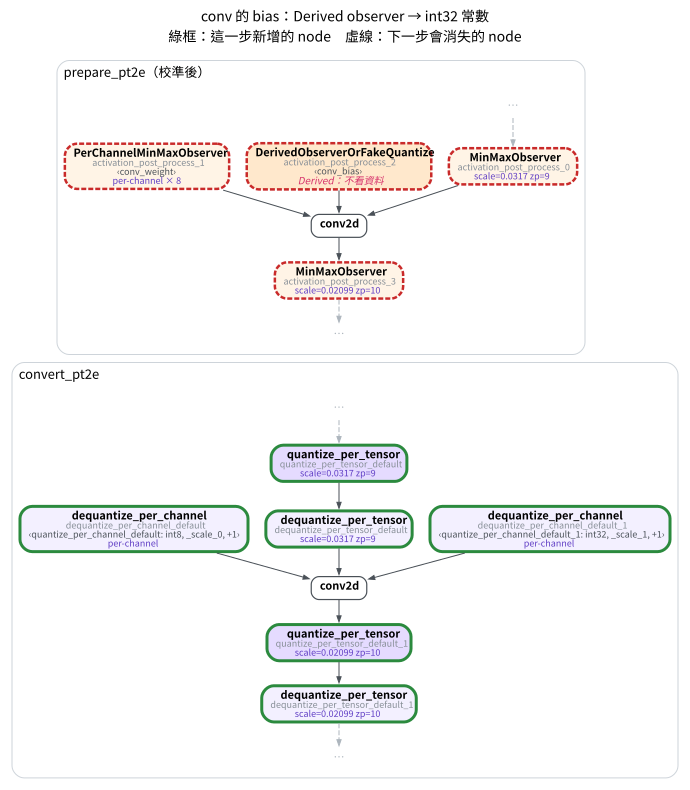

In [3]:
model = get_model("conv_relu").eval()
prepared = prepare_pt2e(export_module(model, example_inputs(4)), ConvBiasQuantizer())
with torch.no_grad():
    for _ in range(8):
        prepared(torch.randn(4, 3, 16, 16))
converted = convert_pt2e(copy.deepcopy(prepared))

conv = next(n for n in prepared.graph.nodes if n.target == CONV2D)
draw_stages([(prepared, "prepare_pt2e（校準後）"), (converted, "convert_pt2e")], focus="conv2d", per_row=1,
            notes=[{conv.args[2].name: "Derived：不看資料"}, {}], title="conv 的 bias：Derived observer → int32 常數")

請看 bias 這條路：

- prepare 之後，bias 前面也有一個 observer，類別是 `DerivedObserverOrFakeQuantize`。它不記錄任何數值，`calculate_qparams()` 被呼叫時才去問另外兩個 observer。
- convert 之後，bias 變成一個 int32 常數（右邊 `dequantize_per_channel` 標籤裡的 `int32`），經過 dequantize 再進 conv。weight 同樣變成 int8 常數。

驗證式 (1)：bias observer 給出的 scale 等於 activation scale × weight scale：

In [4]:
# get_submodule 的回傳型別是 nn.Module；calculate_qparams 是 observer 的方法，用 Any 表達
act_obs, weight_obs, bias_obs = (cast(Any, prepared.get_submodule(a.target)) for a in conv.args[:3])
act_scale = act_obs.calculate_qparams()[0]
weight_scale = weight_obs.calculate_qparams()[0]
bias_scale = bias_obs.calculate_qparams()[0]
print("bias observer 的類別：", type(bias_obs).__name__)
print(f"scale 個數：activation {act_scale.numel()}、weight {weight_scale.numel()}、bias {bias_scale.numel()}")
print("bias scale 與 activation × weight 的最大差：", float((bias_scale - act_scale * weight_scale).abs().max()))
assert torch.equal(bias_scale, act_scale * weight_scale)

bias observer 的類別： DerivedObserverOrFakeQuantize
scale 個數：activation 1、weight 8、bias 8
bias scale 與 activation × weight 的最大差： 0.0


再從 convert 之後的圖取出 int32 bias，乘回 scale，和原本的 fp32 bias 比：

In [5]:
bias_int32 = next(b for name, b in converted.named_buffers() if name.startswith("_frozen_param") and b.dtype == torch.int32)
restored = bias_int32.to(torch.float32) * bias_scale
error = (restored - model.conv.bias.detach()).abs()
print(f"int32 bias 的 shape：{tuple(bias_int32.shape)}")
print(f"還原後與原 bias 的最大誤差：{float(error.max()):.2e}（半個 scale 的最大值：{float(bias_scale.max() / 2):.2e}）")
assert (error <= bias_scale / 2 + 1e-12).all()

int32 bias 的 shape：(8,)
還原後與原 bias 的最大誤差：2.23e-05（半個 scale 的最大值：2.40e-05）


誤差不超過半個 scale，就是式 (1) 的捨入誤差。$s_x s_w$ 很小，所以 int32 bias 幾乎沒有精度損失。

## B. FixedQParams：值域已知或格式已規定時，不需要校準

sigmoid 的輸出一定落在 (0, 1)。用 uint8、scale $= 1/256$、zero point $= 0$ 就能涵蓋 $[0, 255/256]$，不必看資料：

In [6]:
class SigmoidNet(torch.nn.Module):
    def forward(self, x):
        return torch.sigmoid(x)


class SigmoidQuantizer(Quantizer):
    """只量化 sigmoid 的輸出（輸入保持 fp32，誤差只來自輸出的量化）。"""

    def __init__(self, output_spec):
        self.output_spec = output_spec

    def annotate(self, model):
        for node in model.graph.nodes:
            if node.op == "call_function" and node.target == SIGMOID:
                annotate_output_qspec(node, self.output_spec)
        return model

    def validate(self, model):
        pass


fixed = FixedQParamsQuantizationSpec(
    dtype=torch.uint8, scale=1 / 256, zero_point=0, quant_min=0, quant_max=255, qscheme=torch.per_tensor_affine,
)

和照常校準的 `act_spec()`（MinMax）比。故意讓校準資料範圍很小（`randn × 0.1`），測試資料範圍大得多（`randn × 3`），看兩種 qparams 在測試資料上的誤差：

In [7]:
gm = export_module(SigmoidNet(), (torch.randn(4, 8),))
calib = [torch.randn(4, 8) * 0.1 for _ in range(8)]
test_x = torch.randn(4, 8) * 3

rows = []
for title, spec in [("校準（MinMaxObserver）", act_spec()), ("固定 qparams", fixed)]:
    p = prepare_pt2e(copy.deepcopy(gm), SigmoidQuantizer(spec))
    with torch.no_grad():
        for x in calib:
            p(x)
    obs = observer_nodes(p)[0][1]
    scale, zp = obs.calculate_qparams()
    with torch.no_grad():
        err = float((convert_pt2e(p)(test_x) - torch.sigmoid(test_x)).abs().max())
    rows.append([title, type(obs).__name__, f"{float(scale):.6f}", int(zp), f"{err:.4f}"])
table(rows, ["輸出的 qparams", "observer 類別", "scale", "zero point", "測試資料的最大誤差"])

輸出的 qparams,observer 類別,scale,zero point,測試資料的最大誤差
校準（MinMaxObserver）,MinMaxObserver,0.002261,-128,0.4094
固定 qparams,FixedQParamsObserver,0.003906,0,0.0019


In [8]:
calibrated_err, fixed_err = float(rows[0][4]), float(rows[1][4])
assert fixed_err <= 1 / 512 + 1e-6 < calibrated_err

- 校準資料的範圍小，sigmoid 的輸出只落在 0.5 附近一小段。MinMax 的範圍擴張到含 0 之後，上限也只比 0.5 大一點；測試資料一大，超過上限的輸出全被截斷，誤差很大。
- 固定 qparams 完全不看資料，誤差只剩捨入，最多半個 scale（$1/512$）。

適用於輸出值域在數學上已知的 op：sigmoid (0, 1)、tanh (−1, 1)、softmax (0, 1)。
推論（這裡沒有驗證）：整數硬體常以查表實作這類 op，固定 qparams 讓表的內容不必依賴校準資料。

### 另一種用法：輸出格式由下游規定

sigmoid 的 qparams 是由數學上的值域決定的。另一種情況是由**下游的格式**決定：模型的輸出要直接交給只做整數運算的程式。
例如 speech enhancement 模型輸出的 spectrogram（或 mask），交給後面用定點數運算的 DSP，雙方事先約定輸出是 **Q3.12**：

- Q3.12 是 16-bit 有號定點數：1 個 sign bit、3 個整數 bit、12 個小數 bit，整數 $q$ 代表 $q / 2^{12}$。
- 換成 affine 量化的參數：int16、scale $= 2^{-12}$、zero point $= 0$、整數範圍 $[-32768, 32767]$。可表示 $[-8,\ 8 - 2^{-12}]$，每格 $2^{-12} \approx 0.000244$。

這組 qparams 是介面規格，不能交給校準決定：校準算出的 scale 會隨資料改變，DSP 那邊卻寫死了 $2^{-12}$。
所以在模型最後一個 op 的輸出貼 `FixedQParamsQuantizationSpec`，參數照上面填。這組 int16 的 spec 在 torchao 0.18 上 prepare、convert 都正常。要注意三件事：

1. **超出 $[-8, 8)$ 的值會被 clamp。** 固定 qparams 不會因為資料變大而放寬範圍，要先確認模型輸出真的落在範圍內；不夠的話要和 DSP 改約定（例如 Q4.11：範圍加倍、每格變粗一倍）。校準時的 observer 可以拿來檢查範圍，但不決定 qparams。
2. **convert 之後的 Q/DQ 圖，最後一個 node 仍是 dequantize。** 圖的輸出是 fp32，只是每個值都剛好落在 $2^{-12}$ 的格子上。要交出真正的 int16，得由後端 lowering 時去掉最後的 dq，或在交給 DSP 前乘上 $2^{12}$ 轉成整數，數值完全一致。
3. **QAT 時**，同一份 spec 會變成 `FixedQParamsFakeQuantize`，訓練中模型就看得到 Q3.12 的捨入與 clamp，可以學著把輸出放進範圍內。

## 小結

- `DerivedQuantizationSpec`：qparams 由 `derive_qparams_fn` 從其他位置的 observer 算出；典型用途是 int32 bias，scale $= s_x s_w$。
- `FixedQParamsQuantizationSpec`：qparams 寫死在 spec 裡，不受校準資料影響。適合值域已知的 op，也適合輸出格式由下游規定的情況（例如交給定點 DSP 的 Q3.12）。
- 兩者的位置上仍會插 observer（`DerivedObserverOrFakeQuantize`、`FixedQParamsObserver`），只是 qparams 不由它看到的資料決定。